# **FA23-BAI-064**

# Lab: Implementation of CNNs in Keras
**AIC 380: Artificial Neural Networks and Deep Learning**

Run the cells top to bottom (Runtime > Run all). Each activity has built-in checks that fail loudly if a shape or parameter count is wrong.

| Activity | What it does |
|---|---|
| 1 | Build the convolution + pooling feature extractor |
| 2 | Add Flatten + Dense softmax classifier |
| 3 | Train on MNIST |
| 4 | Evaluate on the test set |

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

keras.utils.set_random_seed(42)  # reproducible weights and shuffling

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU is fine for this lab)")

TensorFlow: 2.21.0
GPU: none (CPU is fine for this lab)


## Activity 1: Implementing a basic CNN model

Two groups of layers:
- Group 1: 32 filters, 5x5 window, then 2x2 max pooling.
- Group 2: 64 filters, 5x5 window, then 2x2 max pooling. Its input depth is the 32 feature maps from group 1.

Expected shapes: 28x28x1 -> 24x24x32 -> 12x12x32 -> 8x8x64 -> 4x4x64.
Expected parameters: Conv1 = (5*5*1+1)*32 = 832, Conv2 = (5*5*32+1)*64 = 51,264, total 52,096.

In [2]:
model = models.Sequential()
model.add(layers.Input(shape=(28, 28, 1)))
model.add(layers.Conv2D(32, (5, 5), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (5, 5), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.summary()

assert model.output_shape == (None, 4, 4, 64), model.output_shape
assert model.count_params() == 52_096, model.count_params()
print("Activity 1 checks passed: output 4x4x64, 52,096 parameters")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,096 (203.50 KB)

 Trainable params: 52,096 (203.50 KB)

 Non-trainable params: 0 (0.00 B)

Activity 1 checks passed: output 4x4x64, 52,096 parameters


## Activity 2: A CNN model for classification

Flatten the 4x4x64 block into 1024 values, then add a Dense layer with 10 softmax outputs (one per digit).

Dense parameters = 1024*10 + 10 = 10,250. Total = 52,096 + 10,250 = 62,346.

In [3]:
model = models.Sequential()
model.add(layers.Input(shape=(28, 28, 1)))
model.add(layers.Conv2D(32, (5, 5), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (5, 5), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(10, activation='softmax'))
model.summary()

assert model.layers[-2].output.shape[-1] == 1024, "Flatten should give 1024 values"
assert model.output_shape == (None, 10), model.output_shape
assert model.count_params() == 62_346, model.count_params()
print("Activity 2 checks passed: 1024 flattened values, 10 outputs, 62,346 parameters")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,346 (243.54 KB)

 Trainable params: 62,346 (243.54 KB)

 Non-trainable params: 0 (0.00 B)

Activity 2 checks passed: 1024 flattened values, 10 outputs, 62,346 parameters


## Activity 3: Training the model on MNIST

Preprocessing:
- `reshape` adds the channel dimension that `Conv2D` expects.
- Dividing by 255 scales pixels to the range 0 to 1.
- `to_categorical` one-hot encodes the labels for `categorical_crossentropy`.

With batch size 100 and 60,000 images there are 600 weight updates per epoch (the `600/600` in the log).
Exact numbers differ slightly from the manual because weight initialisation is random.

In [4]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Raw shapes:", train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype('float32') / 255

test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype('float32') / 255

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

assert train_images.shape == (60000, 28, 28, 1)
assert test_images.shape == (10000, 28, 28, 1)
assert train_labels.shape == (60000, 10) and test_labels.shape == (10000, 10)
assert 0.0 <= train_images.min() and train_images.max() <= 1.0
print("Preprocessing checks passed")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Raw shapes: (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
Preprocessing checks passed


In [5]:
batch_size = 100
epochs = 10

model.compile(loss='categorical_crossentropy',
              optimizer='sgd',
              metrics=['accuracy'])

history = model.fit(train_images, train_labels,
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=1)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 61s 100ms/step - accuracy: 0.7683 - loss: 0.8775
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 82s 101ms/step - accuracy: 0.9258 - loss: 0.2561
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 59s 99ms/step - accuracy: 0.9456 - loss: 0.1881
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 81s 98ms/step - accuracy: 0.9560 - loss: 0.1513
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 81s 97ms/step - accuracy: 0.9625 - loss: 0.1283
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - accuracy: 0.9672 - loss: 0.1127
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 83s 97ms/step - accuracy: 0.9705 - loss: 0.1014
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - accuracy: 0.9729 - loss: 0.0928
Epoch 9/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 58s 96ms/step - accuracy: 0.9747 - loss: 0.0859
Epoch 10/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 58s 96ms/step - accuracy: 0.9759 - loss: 0.0803


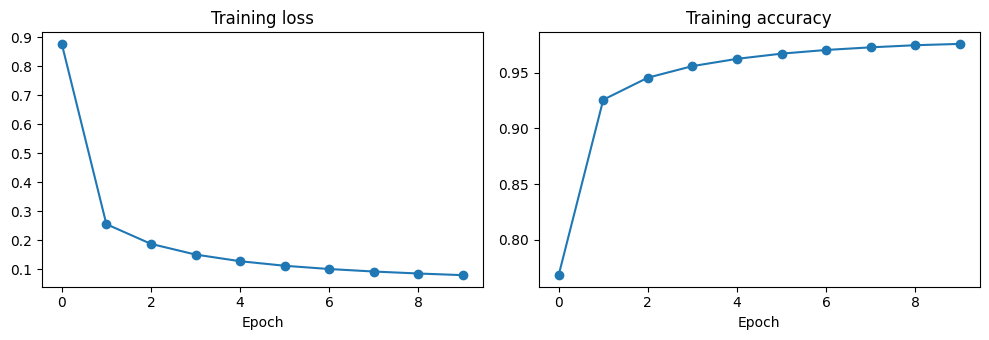

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history['loss'], marker='o')
ax[0].set_title('Training loss'); ax[0].set_xlabel('Epoch')
ax[1].plot(history.history['accuracy'], marker='o')
ax[1].set_title('Training accuracy'); ax[1].set_xlabel('Epoch')
plt.tight_layout()
plt.show()

## Activity 4: Evaluating the model

`evaluate` runs on the 10,000 test images the model never trained on. The default batch size is 32, so you see `313/313` steps (10,000 / 32, rounded up).

In [7]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9758 - loss: 0.0736
Test loss: 0.07360787689685822
Test accuracy: 0.9757999777793884


## Bonus: look at some predictions

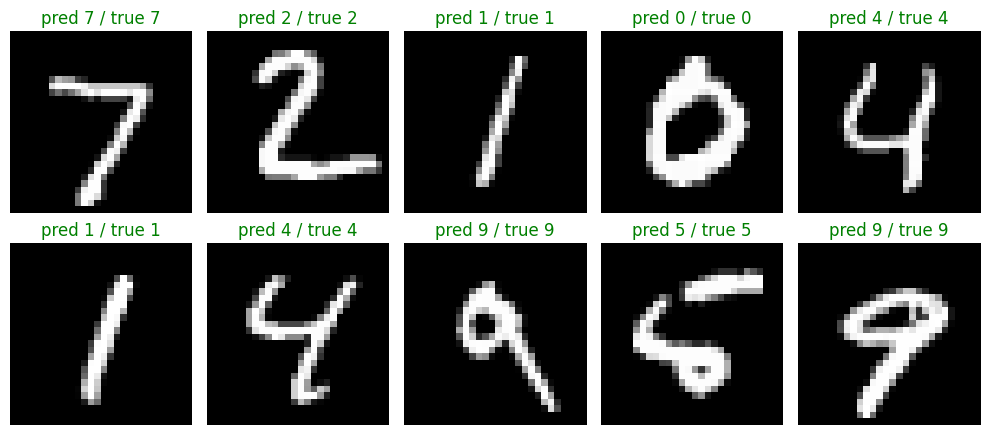

In [8]:
probs = model.predict(test_images[:10], verbose=0)
pred = probs.argmax(axis=1)
true = test_labels[:10].argmax(axis=1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(test_images[i].squeeze(), cmap='gray')
    ax.set_title(f"pred {pred[i]} / true {true[i]}",
                 color='green' if pred[i] == true[i] else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()